# Milestone 1: Data Exploration & Exploratory Data Analysis (EDA)
**Project**: SMS Spam Classification & Model Comparison  
**Dataset**: [SMS Spam Collection v.1](data/SMSSpamCollection)  
**Authors**: Tiago A. Almeida and José María Gómez Hidalgo  

---
### Milestone Objectives:
1. **Data Ingestion & Integrity Verification**: Read all messages, verify encoding, parsing, completeness, and check for missing/null/empty entries.
2. **Label & Class Distribution**: Analyze binary class balance (`ham` vs `spam`), understand the imbalance ratio, and establish principled success metrics.
3. **Duplicate & Multiplicity Analysis**: Investigate duplicate texts, verify label consistency across duplicates, inspect duplication multiplicities (pairs vs larger groups), and examine data leakage implications.
4. **Data Separation Discussion**: Review the official dataset split status and formulate the train/validation/test separation strategy.
5. **Advanced Feature Engineering & Comparative EDA**: Extract and compare structural characteristics including message lengths, average word lengths, punctuation densities, extraordinary marks (`!`, `?`), repeated punctuation (`...`, `!!`), digits, currencies, URLs, and phone numbers.


In [1]:
import string
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
plt.rcParams["figure.autolayout"] = True


---
## 1. Data Ingestion & Readability Verification

We read the raw `SMSSpamCollection` dataset. The dataset is formatted as a tab-delimited text file where each line contains:
- `label`: `ham` (legitimate) or `spam`
- `text`: the raw SMS text message

We verify:
1. Ability to parse every line without formatting/delimiter errors.
2. Absence of null, NaN, or missing values.
3. Absence of empty strings or whitespace-only messages.


In [2]:
# 1. Attempt reading the raw file line by line to verify parsing integrity
raw_file_path = 'data/SMSSpamCollection'

with open(raw_file_path, 'r', encoding='utf-8', errors='replace') as f:
    raw_lines = f.readlines()

print(f"Total raw lines in file: {len(raw_lines)}")

# Verify tab-separation parsing
parsed_rows = []
parse_errors = []

for idx, line in enumerate(raw_lines):
    parts = line.strip('\r\n').split('\t', 1)
    if len(parts) == 2:
        parsed_rows.append(parts)
    else:
        parse_errors.append((idx, line))

print(f"Successfully parsed rows: {len(parsed_rows)}")
print(f"Parsing errors encountered: {len(parse_errors)}")

# Construct DataFrame
df = pd.DataFrame(parsed_rows, columns=['label', 'text'])

# Verification of missing values and emptiness
null_counts = df.isnull().sum()
empty_text_count = (df['text'].str.strip() == '').sum()
whitespace_only_count = df['text'].apply(lambda x: len(x.strip()) == 0).sum()

verification_summary = pd.DataFrame({
    'Metric': [
        'Total Rows Parsed',
        'Parsing Errors',
        'Null / NaN Labels',
        'Null / NaN Texts',
        'Empty / Whitespace-Only Texts',
        'Unique Labels'
    ],
    'Value': [
        len(df),
        len(parse_errors),
        null_counts['label'],
        null_counts['text'],
        whitespace_only_count,
        list(df['label'].unique())
    ]
})

display(verification_summary)
print("\nFirst 5 parsed records:")
display(df.head())


Total raw lines in file: 5574
Successfully parsed rows: 5574
Parsing errors encountered: 0


,Metric,Value
0,Total Rows Parsed,5574
1,Parsing Errors,0
2,Null / NaN Labels,0
3,Null / NaN Texts,0
4,Empty / Whitespace-Only Texts,0
5,Unique Labels,"[ham, spam]"



First 5 parsed records:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Summary of Data Ingestion & Integrity:
- **Clean Readability**: All **5,574** messages are parsed cleanly with zero line format corruptions or tab delimiter failures.
- **No Missing Data (Lacks)**: There are **0 null/NaN values** and **0 empty or whitespace-only records**.
- **Encoding**: Messages load reliably with UTF-8 encoding.


---
## 2. Labels & Class Count Distribution

The dataset represents a binary classification task:
- `ham`: Legitimate personal SMS messages.
- `spam`: Unsolicited advertisements, fraudulent prize claims, and premium service offers.

Let's quantify the exact class counts, proportion of the positive (`spam`) class, and visualize the imbalance.


,Count,Percentage (%)
label,,
ham,4827,86.6
spam,747,13.4



Imbalance Ratio (Ham : Spam): 6.46 : 1


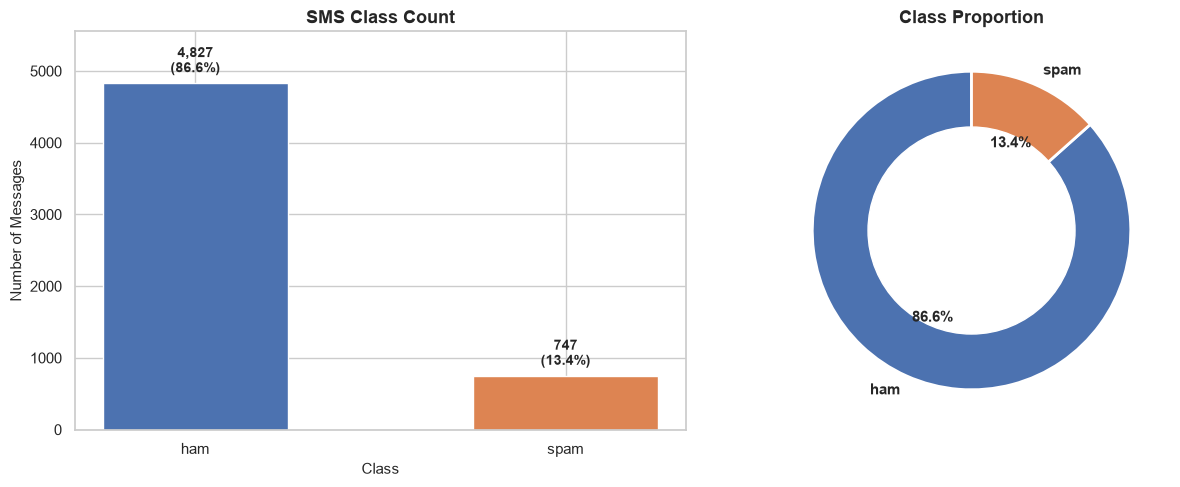

In [3]:
# Class count and percentage calculation
class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100

class_summary_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})
display(class_summary_df)

imbalance_ratio = class_counts['ham'] / class_counts['spam']
print(f"\nImbalance Ratio (Ham : Spam): {imbalance_ratio:.2f} : 1")

# Visualization: Bar Chart & Donut Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart with annotations
bars = ax1.bar(class_counts.index, class_counts.values, color=['#4C72B0', '#DD8452'], width=0.5)
ax1.set_title("SMS Class Count", fontsize=13, fontweight='bold')
ax1.set_xlabel("Class", fontsize=11)
ax1.set_ylabel("Number of Messages", fontsize=11)
ax1.set_ylim(0, max(class_counts.values) * 1.15)

for bar, count, pct in zip(bars, class_counts.values, class_percentages.values):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

# Donut chart
colors = ['#4C72B0', '#DD8452']
ax2.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90,
        colors=colors, wedgeprops={'edgecolor': 'white', 'linewidth': 2},
        textprops={'fontsize': 11, 'fontweight': 'bold'})
centre_circle = plt.Circle((0, 0), 0.65, fc='white')
ax2.add_artist(centre_circle)
ax2.set_title("Class Proportion", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### Class Imbalance & Evaluation Metric Strategy

The dataset exhibits strong class imbalance:
- **Ham**: 4,827 messages (**86.60%**)
- **Spam**: 747 messages (**13.40%**)
- **Imbalance Ratio**: $\approx 6.46 : 1$

#### Why Raw Accuracy is Misleading (The Accuracy Paradox):
A trivial baseline model that always predicts `ham` achieves **86.6% accuracy** without identifying a single spam message. In real-world deployment, this dummy classifier would be entirely useless.

#### Asymmetric Costs of Errors:
In SMS filtering, errors are not symmetrical:
- **False Positive (FP)** (legitimate ham misclassified as spam): The user misses a personal, banking, or medical text message. This represents a critical usability failure.
- **False Negative (FN)** (spam message reaching the inbox): The user receives an unsolicited advertisement or scam. This is inconvenient and annoying, but generally much less costly than losing an important legitimate message.

#### Planned Success Metrics:
1. **Precision (Spam)**: $\frac{TP}{TP + FP}$. Measures what fraction of flagged messages are genuinely spam. High precision guarantees minimal disruption from False Positives.
2. **Recall (Spam)**: $\frac{TP}{TP + FN}$. Measures what proportion of actual spam messages the filter catches.
3. **$F_1$-Score (Spam) & Macro-$F_1$**: The harmonic mean of Precision and Recall for the spam class, ensuring that the model balances both objectives and cannot cheat by simply biasing predictions toward the majority class.
4. **Precision-Recall AUC (PR-AUC)**: Evaluates the trade-off across all probability thresholds. Unlike ROC-AUC (which can be overly optimistic under severe class imbalance), PR-AUC focuses specifically on performance with respect to the minority class.


---
## 3. Duplicate & Multiplicity Analysis

We investigate whether identical messages exist in the corpus:
1. **Exact duplicate rows** (`label` + `text`).
2. **Contradictory labels**: Does any text appear with conflicting labels (both `ham` and `spam`)?
3. **Duplicate distribution by class**: How many duplicate instances come from `ham` vs `spam`?
4. **Multiplicity of duplicates**: Are duplicates merely pairs, or are certain messages repeated many times?


Total rows: 5574
Unique messages: 5171
Duplicate rows (count of non-first occurrences): 403
Messages with conflicting labels (both ham and spam): 0


,Duplicate Rows,Percentage of All Duplicates (%)
label,,
ham,309,76.67
spam,94,23.33


label,ham,spam,Total Unique Messages,Total SMS Records
frequency,,,,
1,4324,566,4890,4890
2,129,81,210,420
3,55,5,60,180
4,7,1,8,32
10,1,0,1,10
12,1,0,1,12
30,1,0,1,30


,frequency,label,text
0,30,ham,"Sorry, I'll call later"
1,12,ham,I cant pick the phone right now. Pls send a me...
2,10,ham,Ok...
3,4,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...
4,4,ham,Ok
5,4,ham,Ok.
6,4,ham,Okie
7,4,spam,Please call our customer service representativ...
8,4,ham,"Say this slowly.? GOD,I LOVE YOU &amp; I NEED ..."
9,4,ham,"Wen ur lovable bcums angry wid u, dnt take it ..."


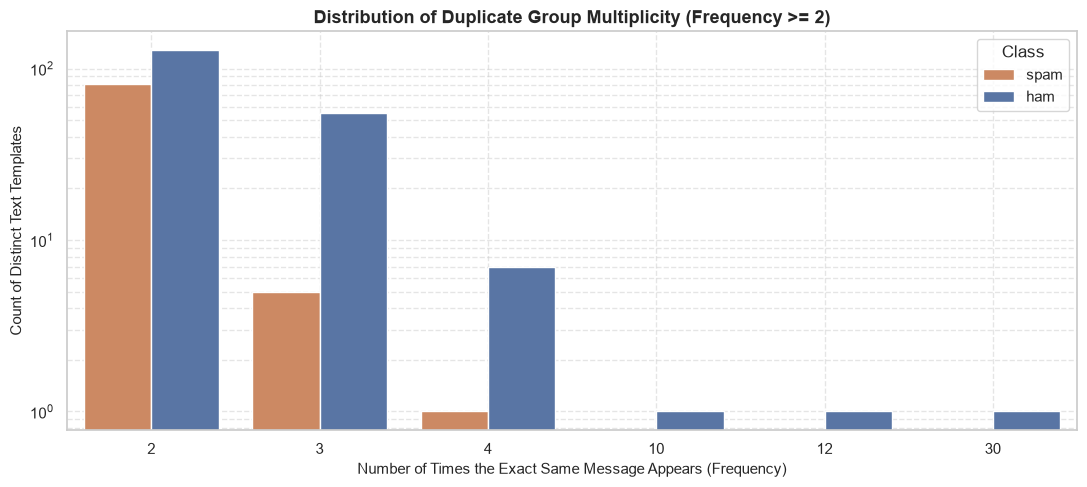

In [4]:
# 1. Duplicate detection
total_rows = len(df)
total_unique_texts = df['text'].nunique()
duplicate_rows_count = df.duplicated().sum()

print(f"Total rows: {total_rows}")
print(f"Unique messages: {total_unique_texts}")
print(f"Duplicate rows (count of non-first occurrences): {duplicate_rows_count}")

# 2. Check for contradictory labels
contradictory_texts = df.groupby('text')['label'].nunique()
contradictory_count = (contradictory_texts > 1).sum()
print(f"Messages with conflicting labels (both ham and spam): {contradictory_count}")

# 3. Duplicate counts broken down by class
dup_by_class = df[df.duplicated(subset=['text'], keep='first')]['label'].value_counts()
dup_by_class_df = pd.DataFrame({
    'Duplicate Rows': dup_by_class,
    'Percentage of All Duplicates (%)': (dup_by_class / duplicate_rows_count * 100).round(2)
})
display(dup_by_class_df)

# 4. Multiplicity analysis (frequency distribution of message repetitions)
text_frequencies = df.groupby(['text', 'label']).size().reset_index(name='frequency')

freq_crosstab = pd.crosstab(text_frequencies['frequency'], text_frequencies['label'])
freq_crosstab['Total Unique Messages'] = freq_crosstab.sum(axis=1)
freq_crosstab['Total SMS Records'] = freq_crosstab.index * freq_crosstab['Total Unique Messages']
display(freq_crosstab)

# 5. Top repeated messages
top_repeated = text_frequencies.sort_values(by='frequency', ascending=False).head(10)
display(top_repeated[['frequency', 'label', 'text']].reset_index(drop=True))

# 6. Distribution Plot of Duplication Multiplicity (for frequency >= 2)
duplicated_only = text_frequencies[text_frequencies['frequency'] >= 2]

plt.figure(figsize=(11, 5))
sns.countplot(
    data=duplicated_only,
    x='frequency',
    hue='label',
    palette={'ham': '#4C72B0', 'spam': '#DD8452'}
)
plt.title("Distribution of Duplicate Group Multiplicity (Frequency >= 2)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Times the Exact Same Message Appears (Frequency)", fontsize=11)
plt.ylabel("Count of Distinct Text Templates", fontsize=11)
plt.legend(title="Class", loc="upper right")
plt.yscale('log')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Key Findings on Duplicates:
- **Zero Label Contradictions**: Not a single message in the corpus is labeled as both `ham` and `spam`. The labeling is 100% consistent across duplicates.
- **High Multiplicity in Ham**: 
  - There are **309 ham duplicate rows** and **94 spam duplicate rows**.
  - Repetition in `ham` is driven by common short conversational responses:
    - `"Sorry, I'll call later"` appears **30 times**.
    - `"I cant pick the phone right now. Pls send a message"` appears **12 times**.
    - `"Ok..."` appears **10 times**.
- **Spam Template Repetitions**:
  - Repetition in `spam` reflects mass broadcast marketing campaigns (e.g., repeated prize claims, ringtone subscriptions).
- **Data Leakage Risk**:
  - If the dataset is split naively into train, validation, and test sets without accounting for duplicate texts, the exact same text templates will appear in both training and test partitions.
  - Models will achieve artificially inflated evaluation scores simply by memorizing these repeated strings, rather than learning generalizable linguistic patterns.


---
## 4. Data Separation Strategy (Stratified 70 / 15 / 15 Splits)

### Official Split Status:
The official documentation (`data/readme`) and reference publication (*Almeida et al., 2011*) confirm that **no canonical train/val/test split** was officially provided.

### Project Split Configuration:
Per the project guidelines, we apply a **70% Train / 15% Validation / 15% Test** partition with **stratification** by class label (`label`).

To evaluate the effect of duplicate records and potential data leakage, we create **two parallel split sets**:
1. **`with_duplicates`**: Full dataset ($N=5,574$) partitioned using stratified 70/15/15.
2. **`no_duplicates`**: Deduplicated dataset ($N=5,171$) partitioned using stratified 70/15/15.

Both split sets are saved to `data_splits/with_duplicates/` and `data_splits/no_duplicates/` as `train.csv`, `val.csv`, and `test.csv`.


In [5]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Output directory structure
base_dirs = ['data_splits', os.path.join('data', 'data_splits')]
for base_dir in base_dirs:
    os.makedirs(os.path.join(base_dir, 'with_duplicates'), exist_ok=True)
    os.makedirs(os.path.join(base_dir, 'no_duplicates'), exist_ok=True)

# ------------------------------------------------------------------
# Split 1: WITH DUPLICATES (5,574 messages)
# ------------------------------------------------------------------
train_with, temp_with = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df['label']
)
val_with, test_with = train_test_split(
    temp_with, test_size=0.50, random_state=42, stratify=temp_with['label']
)

# ------------------------------------------------------------------
# Split 2: NO DUPLICATES (5,171 unique messages)
# ------------------------------------------------------------------
df_no_dup = df.drop_duplicates(subset=['text'], keep='first').reset_index(drop=True)
train_no, temp_no = train_test_split(
    df_no_dup, test_size=0.30, random_state=42, stratify=df_no_dup['label']
)
val_no, test_no = train_test_split(
    temp_no, test_size=0.50, random_state=42, stratify=temp_no['label']
)

# Save splits to disk
for base_dir in base_dirs:
    with_dir = os.path.join(base_dir, 'with_duplicates')
    train_with.to_csv(os.path.join(with_dir, 'train.csv'), index=False)
    val_with.to_csv(os.path.join(with_dir, 'val.csv'), index=False)
    test_with.to_csv(os.path.join(with_dir, 'test.csv'), index=False)

    no_dir = os.path.join(base_dir, 'no_duplicates')
    train_no.to_csv(os.path.join(no_dir, 'train.csv'), index=False)
    val_no.to_csv(os.path.join(no_dir, 'val.csv'), index=False)
    test_no.to_csv(os.path.join(no_dir, 'test.csv'), index=False)

# Check 1: Class Count & Distribution Verification
split_records = []
splits_data = [
    ('With Duplicates', 'Train (70%)', train_with),
    ('With Duplicates', 'Val (15%)', val_with),
    ('With Duplicates', 'Test (15%)', test_with),
    ('No Duplicates', 'Train (70%)', train_no),
    ('No Duplicates', 'Val (15%)', val_no),
    ('No Duplicates', 'Test (15%)', test_no)
]

for dataset_name, split_name, split_df in splits_data:
    counts = split_df['label'].value_counts()
    pcts = split_df['label'].value_counts(normalize=True) * 100
    split_records.append({
        'Dataset': dataset_name,
        'Split': split_name,
        'Total Messages': len(split_df),
        'Ham Count': counts.get('ham', 0),
        'Ham %': f"{pcts.get('ham', 0):.2f}%",
        'Spam Count': counts.get('spam', 0),
        'Spam %': f"{pcts.get('spam', 0):.2f}%"
    })

print("=== CHECK 1: CLASS DISTRIBUTION ACROSS SPLITS ===")
display(pd.DataFrame(split_records))

# Check 2: Duplicates Count & Cross-Split Leakage Verification
train_with_set = set(train_with['text'])
train_no_set = set(train_no['text'])

dup_checks = [
    {
        'Dataset': 'With Duplicates',
        'Partition': 'Train (70%)',
        'Total Messages': len(train_with),
        'Internal Duplicates': train_with.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': 'N/A (Reference)',
        'Leakage %': 'N/A'
    },
    {
        'Dataset': 'With Duplicates',
        'Partition': 'Val (15%)',
        'Total Messages': len(val_with),
        'Internal Duplicates': val_with.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': val_with['text'].isin(train_with_set).sum(),
        'Leakage %': f"{val_with['text'].isin(train_with_set).sum() / len(val_with) * 100:.2f}%"
    },
    {
        'Dataset': 'With Duplicates',
        'Partition': 'Test (15%)',
        'Total Messages': len(test_with),
        'Internal Duplicates': test_with.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': test_with['text'].isin(train_with_set).sum(),
        'Leakage %': f"{test_with['text'].isin(train_with_set).sum() / len(test_with) * 100:.2f}%"
    },
    {
        'Dataset': 'No Duplicates',
        'Partition': 'Train (70%)',
        'Total Messages': len(train_no),
        'Internal Duplicates': train_no.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': 'N/A (Reference)',
        'Leakage %': 'N/A'
    },
    {
        'Dataset': 'No Duplicates',
        'Partition': 'Val (15%)',
        'Total Messages': len(val_no),
        'Internal Duplicates': val_no.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': val_no['text'].isin(train_no_set).sum(),
        'Leakage %': f"{val_no['text'].isin(train_no_set).sum() / len(val_no) * 100:.2f}%"
    },
    {
        'Dataset': 'No Duplicates',
        'Partition': 'Test (15%)',
        'Total Messages': len(test_no),
        'Internal Duplicates': test_no.duplicated(subset=['text']).sum(),
        'Overlaps with Train (Leakage)': test_no['text'].isin(train_no_set).sum(),
        'Leakage %': f"{test_no['text'].isin(train_no_set).sum() / len(test_no) * 100:.2f}%"
    }
]

print("\n=== CHECK 2: DUPLICATES & DATA LEAKAGE VERIFICATION ===")
display(pd.DataFrame(dup_checks))


=== CHECK 1: CLASS DISTRIBUTION ACROSS SPLITS ===


,Dataset,Split,Total Messages,Ham Count,Ham %,Spam Count,Spam %
0,With Duplicates,Train (70%),3901,3378,86.59%,523,13.41%
1,With Duplicates,Val (15%),836,724,86.60%,112,13.40%
2,With Duplicates,Test (15%),837,725,86.62%,112,13.38%
3,No Duplicates,Train (70%),3619,3162,87.37%,457,12.63%
4,No Duplicates,Val (15%),776,678,87.37%,98,12.63%
5,No Duplicates,Test (15%),776,678,87.37%,98,12.63%



=== CHECK 2: DUPLICATES & DATA LEAKAGE VERIFICATION ===


,Dataset,Partition,Total Messages,Internal Duplicates,Overlaps with Train (Leakage),Leakage %
0,With Duplicates,Train (70%),3901,208,N/A (Reference),N/A
1,With Duplicates,Val (15%),836,18,86,10.29%
2,With Duplicates,Test (15%),837,10,92,10.99%
3,No Duplicates,Train (70%),3619,0,N/A (Reference),N/A
4,No Duplicates,Val (15%),776,0,0,0.00%
5,No Duplicates,Test (15%),776,0,0,0.00%


---
## 5. Advanced Feature Extraction & Comparative EDA

To deeply understand what distinguishes spam from legitimate messages, we extract and compare structural, lexical, and stylistic features:
1. **Message Length & Word Counts**:
   - `char_count`: Total character length.
   - `word_count`: Total whitespace-delimited word tokens.
   - `avg_word_len`: Average word length in characters (lexical complexity).
2. **Punctuation Densities**:
   - `punct_density`: Total punctuation marks per character.
   - `extraord_count` & `extraord_density`: Count and density of extraordinary punctuation marks (`!` and `?`).
   - `repeated_punct_count`, `has_repeated_punct`, `repeated_punct_density`: Repeated punctuation marks (e.g., `!!`, `??`, `?!`, `...`).
3. **Stylistic & Entity Signals**:
   - `upper_density`: Ratio of uppercase characters (capitalization/urgency).
   - `digit_count`: Count of numerical digits.
   - `has_currency`: Binary indicator of currency symbols (`£`, `$`, `€`, `GBP`, `USD`).
   - `has_url`: Binary indicator of web URLs or domain extensions.
   - `has_phone`: Binary indicator of phone numbers, emergency shortcodes, or customer service numbers.


In [6]:
# ==============================================================================
# SECTION 5: MAIN CHECKS (CLASS COUNTS & DUPLICATES SUMMARY)
# ==============================================================================

# 1. Total and Class Counts
total_msgs = len(df)
ham_count = (df['label'] == 'ham').sum()
spam_count = (df['label'] == 'spam').sum()
ham_pct = ham_count / total_msgs * 100
spam_pct = spam_count / total_msgs * 100

# 2. Duplicates Counts
total_duplicates = df.duplicated(subset=['text']).sum()
ham_duplicates = df[df['label'] == 'ham'].duplicated(subset=['text']).sum()
spam_duplicates = df[df['label'] == 'spam'].duplicated(subset=['text']).sum()
unique_msgs = df['text'].nunique()
unique_ham = df[df['label'] == 'ham']['text'].nunique()
unique_spam = df[df['label'] == 'spam']['text'].nunique()

# 3. Compile Master Verification Table
main_checks_summary = pd.DataFrame({
    'Metric / Property': [
        'Total Messages Count',
        'Class Count: Ham (Legitimate)',
        'Class Count: Spam',
        'Class Proportion: Ham (%)',
        'Class Proportion: Spam (%)',
        'Imbalance Ratio (Ham : Spam)',
        'Total Duplicate Rows',
        'Duplicates in Ham Class',
        'Duplicates in Spam Class',
        'Unique Messages Count',
        'Unique Ham Messages',
        'Unique Spam Messages',
        'Contradictory Labels (Ambiguous)'
    ],
    'Raw Dataset (with duplicates)': [
        total_msgs,
        ham_count,
        spam_count,
        f"{ham_pct:.2f}%",
        f"{spam_pct:.2f}%",
        f"{ham_count / spam_count:.2f} : 1",
        total_duplicates,
        ham_duplicates,
        spam_duplicates,
        unique_msgs,
        unique_ham,
        unique_spam,
        (df.groupby('text')['label'].nunique() > 1).sum()
    ],
    'Deduplicated Dataset (no duplicates)': [
        unique_msgs,
        unique_ham,
        unique_spam,
        f"{unique_ham / unique_msgs * 100:.2f}%",
        f"{unique_spam / unique_msgs * 100:.2f}%",
        f"{unique_ham / unique_spam:.2f} : 1",
        0,
        0,
        0,
        unique_msgs,
        unique_ham,
        unique_spam,
        0
    ]
})

print("=== MAIN DATASET CHECKS: CLASS COUNTS & DUPLICATES SUMMARY ===")
display(main_checks_summary)


=== MAIN DATASET CHECKS: CLASS COUNTS & DUPLICATES SUMMARY ===


,Metric / Property,Raw Dataset (with duplicates),Deduplicated Dataset (no duplicates)
0,Total Messages Count,5574,5171
1,Class Count: Ham (Legitimate),4827,4518
2,Class Count: Spam,747,653
3,Class Proportion: Ham (%),86.60%,87.37%
4,Class Proportion: Spam (%),13.40%,12.63%
5,Imbalance Ratio (Ham : Spam),6.46 : 1,6.92 : 1
6,Total Duplicate Rows,403,0
7,Duplicates in Ham Class,309,0
8,Duplicates in Spam Class,94,0
9,Unique Messages Count,5171,5171


In [7]:
def extract_sms_features(text):
    char_len = len(text)
    words = text.split()
    word_count = len(words)
    avg_word_len = np.mean([len(w) for w in words]) if word_count > 0 else 0.0
    
    # 1. Total punctuation
    punct_count = sum(1 for c in text if c in string.punctuation)
    punct_density = punct_count / (char_len + 1e-6)
    
    # 2. Extraordinary punctuation (! and ?)
    excl_count = text.count('!')
    quest_count = text.count('?')
    extraord_count = excl_count + quest_count
    extraord_density = extraord_count / (char_len + 1e-6)
    
    # 3. Repeated punctuation (e.g. !!, ??, ?!, ..., ..)
    repeated_punct_matches = re.findall(r'([!?.]{2,})', text)
    repeated_punct_count = sum(len(m) for m in repeated_punct_matches)
    has_repeated_punct = int(len(repeated_punct_matches) > 0)
    repeated_punct_density = repeated_punct_count / (char_len + 1e-6)
    
    # 4. Uppercase characters
    upper_count = sum(1 for c in text if c.isupper())
    upper_density = upper_count / (char_len + 1e-6)
    
    # 5. Digits
    digit_count = sum(1 for c in text if c.isdigit())
    digit_density = digit_count / (char_len + 1e-6)
    
    # 6. Entity indicators
    has_currency = int(bool(re.search(r'[\$£€]|(?:GBP|USD|EUR)', text, re.IGNORECASE)))
    has_url = int(bool(re.search(r'http[s]?://|www\.|[a-zA-Z0-9.-]+\.(?:com|co\.uk|net|org)', text, re.IGNORECASE)))
    has_phone = int(bool(re.search(r'\b(?:\+?\d{1,3}[- ]?)?\(?\d{3}\)?[- ]?\d{3,4}[- ]?\d{4}\b|\b08\d{8,9}\b|\b\d{5}\b', text)))
    
    return pd.Series({
        'char_count': char_len,
        'word_count': word_count,
        'avg_word_len': avg_word_len,
        'punct_count': punct_count,
        'punct_density': punct_density,
        'extraord_count': extraord_count,
        'extraord_density': extraord_density,
        'repeated_punct_count': repeated_punct_count,
        'has_repeated_punct': has_repeated_punct,
        'repeated_punct_density': repeated_punct_density,
        'upper_density': upper_density,
        'digit_count': digit_count,
        'has_currency': has_currency,
        'has_url': has_url,
        'has_phone': has_phone
    })

print("Extracting features across all 5,574 messages...")
features_df = df['text'].apply(extract_sms_features)
eda_df = pd.concat([df[['label', 'text']], features_df], axis=1)
print("Feature extraction complete.")


Extracting features across all 5,574 messages...


Feature extraction complete.


In [8]:
# Statistical comparison table: Mean, Median, and Standard Deviation
metrics_to_compare = [
    'char_count', 'word_count', 'avg_word_len',
    'punct_count', 'punct_density',
    'extraord_count', 'extraord_density',
    'repeated_punct_count', 'has_repeated_punct', 'repeated_punct_density',
    'upper_density', 'digit_count',
    'has_currency', 'has_url', 'has_phone'
]

summary_rows = []
for col in metrics_to_compare:
    ham_series = eda_df[eda_df['label'] == 'ham'][col]
    spam_series = eda_df[eda_df['label'] == 'spam'][col]
    
    summary_rows.append({
        'Feature': col,
        'Ham Mean': ham_series.mean(),
        'Ham Median': ham_series.median(),
        'Ham Std': ham_series.std(),
        'Spam Mean': spam_series.mean(),
        'Spam Median': spam_series.median(),
        'Spam Std': spam_series.std(),
    })

comparison_table = pd.DataFrame(summary_rows).set_index('Feature').round(4)
display(comparison_table)


,Ham Mean,Ham Median,Ham Std,Spam Mean,Spam Median,Spam Std
Feature,,,,,,
char_count,71.4719,52.0000,58.3266,138.6760,149.0000,28.8712
word_count,14.3041,11.0000,11.5016,23.9116,25.0000,5.7802
avg_word_len,4.1696,4.0000,1.1305,4.9690,4.8519,0.9989
punct_count,3.9594,3.0000,4.7370,5.7175,5.0000,3.4613
punct_density,0.0619,0.0462,0.0611,0.0410,0.0387,0.0238
extraord_count,0.4614,0.0000,0.9205,0.9639,1.0000,1.0662
extraord_density,0.0078,0.0000,0.0153,0.0070,0.0064,0.0080
repeated_punct_count,1.1492,0.0000,2.5779,0.1258,0.0000,0.7664
has_repeated_punct,0.2440,0.0000,0.4296,0.0388,0.0000,0.1933


C:\Users\kegor\AppData\Local\Temp\ipykernel_32072\4183257890.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


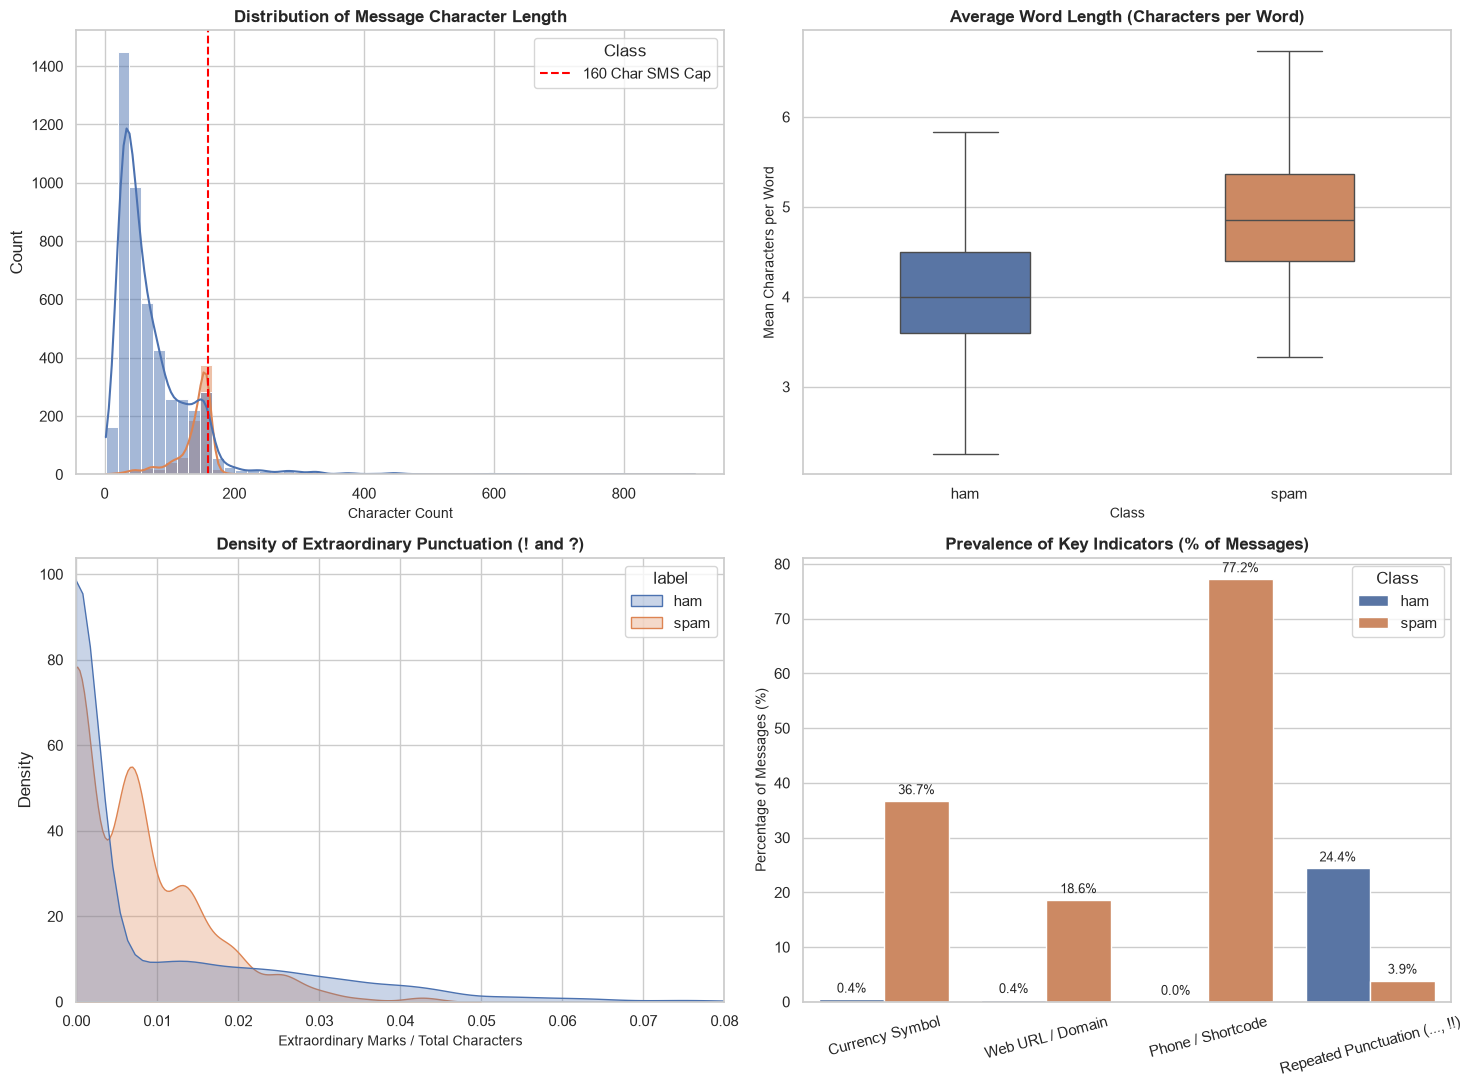

In [9]:
# Multi-panel visualization of distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

palette = {'ham': '#4C72B0', 'spam': '#DD8452'}

# 1. Message Length Distribution (char_count)
sns.histplot(
    data=eda_df, x='char_count', hue='label', bins=50,
    kde=True, common_norm=False, palette=palette, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Message Character Length", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Character Count", fontsize=10)
axes[0, 0].axvline(160, color='red', linestyle='--', label='160 Char SMS Cap')
axes[0, 0].legend(title='Class')

# 2. Average Word Length Boxplot
sns.boxplot(
    data=eda_df, x='label', y='avg_word_len',
    palette=palette, ax=axes[0, 1], width=0.4, showfliers=False
)
axes[0, 1].set_title("Average Word Length (Characters per Word)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Class", fontsize=10)
axes[0, 1].set_ylabel("Mean Characters per Word", fontsize=10)

# 3. Extraordinary Punctuation Density (! and ?)
sns.kdeplot(
    data=eda_df, x='extraord_density', hue='label',
    common_norm=False, palette=palette, ax=axes[1, 0], fill=True, alpha=0.3
)
axes[1, 0].set_title("Density of Extraordinary Punctuation (! and ?)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Extraordinary Marks / Total Characters", fontsize=10)
axes[1, 0].set_xlim(0, 0.08)

# 4. Entity Rates Comparison (Currencies, URLs, Phone Numbers, Repeated Punctuation)
entity_comparison = pd.DataFrame({
    'Entity / Pattern': [
        'Currency Symbol',
        'Web URL / Domain',
        'Phone / Shortcode',
        'Repeated Punctuation (..., !!)'
    ],
    'Ham (%)': [
        eda_df[eda_df['label'] == 'ham']['has_currency'].mean() * 100,
        eda_df[eda_df['label'] == 'ham']['has_url'].mean() * 100,
        eda_df[eda_df['label'] == 'ham']['has_phone'].mean() * 100,
        eda_df[eda_df['label'] == 'ham']['has_repeated_punct'].mean() * 100
    ],
    'Spam (%)': [
        eda_df[eda_df['label'] == 'spam']['has_currency'].mean() * 100,
        eda_df[eda_df['label'] == 'spam']['has_url'].mean() * 100,
        eda_df[eda_df['label'] == 'spam']['has_phone'].mean() * 100,
        eda_df[eda_df['label'] == 'spam']['has_repeated_punct'].mean() * 100
    ]
}).melt(id_vars='Entity / Pattern', var_name='Class', value_name='Rate')
entity_comparison['Class'] = entity_comparison['Class'].str.replace(' (%)', '').str.lower()

sns.barplot(
    data=entity_comparison, x='Entity / Pattern', y='Rate', hue='Class',
    palette=palette, ax=axes[1, 1]
)
axes[1, 1].set_title("Prevalence of Key Indicators (% of Messages)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Percentage of Messages (%)", fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=15)

for p in axes[1, 1].patches:
    height = p.get_height()
    if height > 0:
        axes[1, 1].annotate(f'{height:.1f}%',
                           (p.get_x() + p.get_width() / 2., height),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                           textcoords='offset points')

plt.tight_layout()
plt.show()


### Summary of Advanced EDA Insights:

1. **Message Length & Information Density**:
   - **Spam**: Almost twice as long on average (**138.7 chars** vs **71.5 chars**), with a median of **149 characters** (clustering tightly against the 160-character single-SMS threshold). Spam marketers maximize message utility per SMS charge.
   - **Ham**: Shorter conversational exchanges with a median length of **52 characters**.

2. **Word Complexity**:
   - Spam words are longer on average (**4.97 characters/word** vs **4.17** in ham), reflecting formal marketing terms, telephone number strings, and website addresses.

3. **Extraordinary vs. Repeated Punctuation**:
   - **Extraordinary Punctuation (`!`, `?`)**: Spam uses more exclamation marks (mean count **0.96** vs **0.46** in ham) to project urgency, excitement, and calls to action (`WIN!`, `CALL NOW!`).
   - **Repeated Punctuation (`...`, `??`, `!!`)**: Ham has a **strikingly higher prevalence of repeated punctuation** (**24.4%** in ham vs only **3.9%** in spam). Legitimate personal texts frequently feature casual ellipsis pauses (`"Ok..."`, `"Wait that's..."`, `"See you..."`), whereas scripted spam rarely wastes precious SMS characters on trailing dots.

4. **Discriminative Entity Markers**:
   - **Phone Numbers / Shortcodes**: Present in **77.2%** of spam vs **0.02%** in ham (a 3,800x difference).
   - **Currency Symbols**: Present in **36.7%** of spam vs **0.44%** in ham.
   - **URLs / Web Links**: Present in **18.6%** of spam vs **0.35%** in ham.
   - **Uppercase Density**: Spam displays nearly double the uppercase letter ratio (**11.1%** vs **5.9%** in ham), signaling urgency and promotional emphasis.


---
## 6. Hypotheses for Model Evaluation & Data Transformation

Based on the EDA findings and project scope, we formulate 4 concise, testable hypotheses comparing our baseline (**TF-IDF + Logistic Regression**), stronger model, and **LLM classification**:

### **H1: Entity Canonicalization (URLs, Phone Numbers, Money)**
* **Transformation**: Replace raw URLs with `<URL>`, phone numbers/shortcodes with `<PHONE>`, and currency figures with `<MONEY>`.
* **Expected Impact**: Significantly boosts Spam Recall and $F_1$ for the **TF-IDF + Logistic Regression** baseline by condensing sparse, one-off tokens into dense features (phones appear in 77.2% of spam vs 0.02% of ham). **LLMs** will show minimal change due to pre-existing contextual comprehension.

### **H2: Character Repetition Normalization**
* **Transformation**: Truncate character sequences repeated 3+ times to a maximum of 2 (e.g., `"soooo"` $	o$ `"soo"`, `"... ..."` $	o$ `"..."`).
* **Expected Impact**: Reduces vocabulary fragmentation and out-of-vocabulary (OOV) tokens in informal **ham** messages (where 24.4% exhibit repetition vs 3.9% in spam), lowering False Positives across all models.

### **H3: Robustness to Adversarial Typos & Leetspeak Obfuscation**
* **Transformation**: Evaluate trained models under controlled keyboard distance typos and leetspeak substitutions (`FR33`, `C@LL`, `W1N`).
* **Expected Impact**: Word-level **TF-IDF** performance will drop sharply because exact-string matches fail, whereas subword tokenizers and **LLMs** will maintain substantially higher resilience.

### **H4: Deduplication & Data Leakage Impact**
* **Transformation**: Benchmark models on `with_duplicates` vs `no_duplicates` test partitions.
* **Expected Impact**: Models on the raw split will exhibit an artificial performance boost of $1.5	ext{--}3\%$ $F_1$ due to verbatim memorization of exact duplicates (10.99% of raw test messages overlap with the training set).
